<center><p float="center">
  <img src="https://images.pexels.com/photos/3184465/pexels-photo-3184465.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" width="720"/>
</p></center>

<center><font size=6>Job Change Prediction</font></center>

## Problem Statement

### Businees Context

The Ed Tech companies working on data science usually receive many
registrations for the training programs of the companies before officially
giving them a permanent role. Among those trainees, the companies want
to know which candidates are really want to work for them or will look
for a new employment after training time. This will help to reduce the
training cost, and bring higher levels of satisfaction and retention. This
work is performed to interpret the main factors impacting to candidate
decision and then build a prediction model to predict the probability of a
candidate will look for a new job or will work for the company using the
current credentials, demographics, experience data, etc.

### Objective
Ed Tech company wants to predict the likelihood of the candidates with
the intention to leave or do not leave the company after training periods. As data scientist at this Ed Tech company,you need to work on these and interpret the main factors impacting to candidate decision
and then build a prediction model to predict the probability of a candidate will
look for a new job or will work for the company using the current credentials,
demographics, experience data, etc.


### Data Description

* enrollee_id: Unique ID for the candidate

* city: City code

* city_ development _index: Development index of the city (scaled)

* gender: Gender of the candidate

* relevent_experience: Relevant experience of the candidate

* enrolled_university: Type of University course enrolled if any

* education_level: Education level of candidate

* major_discipline: Education major discipline of the candidate

* experience: Candidate total experience in years

* company_size: No of employees in current employer's company

* company_type: Type of current employer

* lastnewjob: Difference in years between previous job and current job

* training_hours: training hours completed

* target: 0 – Not looking for a job change, 1 – Looking for a job change


#### What is City Development Index?

* The City Development Index was developed for the Second United Nations Conference on Human Settlements (Habitat II) in 1996 and measures the level of development in cities. The Urban Indicators Programme of the United Nations Human Settlements Programme (UN-Habitat) developed the indicator so that they could rank cities of the world according to their level of development and as a display of indicators depicting development. The CDI cuts across the different clusters identified in the Urban Indicator Framework as it is based on five sub-indices namely, infrastructure, waste, health, education, and city product. It is useful as it provides a snap-shot view of how cities are doing concerning the different indices

## Importing necessary libraries

In [87]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores and split data
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# To impute missing values
from sklearn.impute import SimpleImputer

# To build a logistic regression model
from sklearn.linear_model import LogisticRegression

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To suppress the warnings
import warnings

warnings.filterwarnings("ignore")


## Loading the Dataset

In [88]:
# load dataset
df = pd.read_csv("jobs_data.csv")

## Data Overview

The initial steps to get an overview of any dataset is to:
- observe the first few rows of the dataset, to check whether the dataset has been loaded properly or not
- get information about the number of rows and columns in the dataset
- find out the data types of the columns to ensure that data is stored in the preferred format and the value of each property is as expected.
- check the statistical summary of the dataset to get an overview of the numerical columns of the data

### Displaying the first few rows of the dataset

In [89]:
# To view the first 5 entries in the dataset
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


### Checking the shape of the dataset


In [90]:
# To view the number of rows and columns in the dataset
df.shape

(19158, 14)

### Checking the data types of the columns for the dataset

In [91]:
# To check the data types of the columns in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

* Only 4 variables are numerical rest all are object types.
* 9 columns have less than 19158 non-null values i.e. columns have missing values.

### Statistical summary of the dataset

In [92]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,NaN,NaN,NaN,16875.358179,9616.292592,1.0,8554.25,16982.5,25169.75,33380.0
city,19158,123,city_103,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_development_index,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
gender,14650,3,Male,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relevent_experience,19158,2,Has relevent experience,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enrolled_university,18772,3,no_enrollment,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,18698,5,Graduate,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
major_discipline,16345,6,STEM,14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience,19093,22,>20,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,13220,8,50-99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**
* `city_developement_index:` Since the value of the city development index is normalized a 0.82 average value indicates that most of the data we have is from fairly developed cities (metropolitan cities). However, the range of the index is large and varies from 0.448 to 0.949.
* `training_hours:` Training hours have a wide range from 60hrs to 336hrs. On average, an enrollee has 65hrs of training. 755 of the enrollees less than (or equal to) 88hrs of training.
* `target:` It shows an imbalance with 75% of enrollees not seeking jobs and possibly just interested in new technologies.

In [93]:
# To view the statistical summary of the non-numerical columns in the data
df.describe(include="object").T

,count,unique,top,freq
city,19158,123,city_103,4355
gender,14650,3,Male,13221
relevent_experience,19158,2,Has relevent experience,13792
enrolled_university,18772,3,no_enrollment,13817
education_level,18698,5,Graduate,11598
major_discipline,16345,6,STEM,14492
experience,19093,22,>20,3286
company_size,13220,8,50-99,3083
company_type,13018,6,Pvt Ltd,9817
last_new_job,18735,6,1,8040


**Observations**
* Most of the records are from city_103.
* Most of the enrollees are Males.
* Most enrollees have some relevant experience.
* Most of the enrollees were not enrolled in a university.
* Most of the enrollees are graduates.
* Most of the enrollees have STEM as their major discipline.
* Most enrollees have worked in a pvt_ltd company.

In [94]:
# categorical values
cat_col = df.columns

# printing the number of occurrences of each unique value in each categorical column
for col in cat_col:
    print(f"{col}:")
    print(df[col].value_counts())
    print("-" * 50)

enrollee_id:
enrollee_id
8949     1
29725    1
11561    1
33241    1
666      1
        ..
7386     1
31398    1
24576    1
5756     1
23834    1
Name: count, Length: 19158, dtype: int64
--------------------------------------------------
city:
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_129       3
city_121       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64
--------------------------------------------------
city_development_index:
city_development_index
0.920    5200
0.624    2702
0.910    1533
0.926    1336
0.698     683
         ... 
0.649       4
0.807       4
0.781       3
0.625       3
0.664       1
Name: count, Length: 93, dtype: int64
--------------------------------------------------
gender:
gender
Male      13221
Female     1238
Other       191
Name: count, dtype: int64
--------------------------------------------------
relevent_experience:
relevent_experience
Has

### Checking for duplicate values



In [95]:
# To check for duplicate values in the data

df.duplicated().sum()

np.int64(0)

* There are no duplicate values in the data



### Checking for missing values

In [96]:
# To check the percentage of missing values in each row
round(df.isnull().sum() / df.isnull().count() * 100, 2)

,0
enrollee_id,0.00
city,0.00
city_development_index,0.00
gender,23.53
relevent_experience,0.00
enrolled_university,2.01
education_level,2.40
major_discipline,14.68
experience,0.34
company_size,30.99


* `company_type` column has 32.05% missing values out of the total observations.
* `company_size` column has 30.99% missing values out of the total observations.
* `gender` column has 23.53% missing values out of the total observations.
* `major_discipline` column has 14.68% missing values out of the total observations.
* `education_level` column has 2.40% missing values out of the total observations.
* `last_new_job` column has 2.21% missing values out of the total observations.
* `enrolled_university` column has 2.01% missing values out of the total observations.
* `experience` column has 0.34% missing values out of the total observations.
* We will impute these values after we split the data into train, validation and test sets.

## Exploratory Data Analysis (EDA)

**Functions defined to carry out the EDA**

In [97]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12,7), kde=False, bins=None):
    """
    Documentation:
    Boxplot and histogram combined
    - data: dataframe
    - feature: numerical column
    - figsize: size of figure (default (12,7))
    - kde: whether to show the density curve
    - bins: number of bars/groups for histogram
    """

# using matplotlib.pyplot to create multiple plots
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of plots = 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize, # default size
    )  # creating the 2 subplots


 # boxplot will be created and a triangle will indicate the mean value of the column
    sns.boxplot(
        data=data,
        x=feature,
        ax=ax_box2,
        showmeans=True,
        color="violet"
    )
    # For histogram
    sns.histplot(
        data=data,
        x=feature,
        kde=kde,
        ax=ax_hist2,
        bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )

    # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )

    # Add median to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )

In [98]:
# function to create a labeled barplot

def labeled_barplot(data, feature, perc=False, n=None):
    """
    Documentation:
    Barplot with count or percentage labels at the top
    - data: dataframe
    - feature: categorical column
    - perc: whether to display percentages instead of count
    - n: displays the top n category levels
        (default is None, i.e., display all levels)
    """

    # total number of values in the selected column
    total = len(data[feature])

    # number of unique categories in the selected column
    count = data[feature].nunique()

    # setting the figure size
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    # rotating x-axis labels for better readability
    plt.xticks(rotation=90, fontsize=15)

    # creating the countplot
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    # adding labels on top of each bar
    for p in ax.patches:

        # display percentage if perc=True
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )

        # otherwise display the count
        else:
            label = p.get_height()

        # finding the center of the bar
        x = p.get_x() + p.get_width() / 2

        # finding the height of the bar
        y = p.get_height()

        # adding the label to the bar
        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )

    # display the plot
    plt.show()

In [99]:
# function to plot a stacked bar chart

def stacked_barplot(data, predictor, target):
    """
    Documentation:
    Print category counts and plot a stacked bar chart
    - data: dataframe
    - predictor: independent/categorical variable
    - target: target/categorical variable
    """

    # number of unique categories in the predictor
    count = data[predictor].nunique()

    # finding the last category of the target based on its value counts
    sorter = data[target].value_counts().index[-1]

    # creating a cross-tabulation table showing category counts
    tab1 = pd.crosstab(
        data[predictor],
        data[target],
        margins=True
    ).sort_values(
        by=sorter,
        ascending=False
    )

    # printing the category counts
    print(tab1)

    # printing a separator line
    print("-" * 120)

    # creating a cross-tabulation table with percentages
    # normalize="index" calculates percentages row-wise
    tab = pd.crosstab(
        data[predictor],
        data[target],
        normalize="index"
    ).sort_values(
        by=sorter,
        ascending=False
    )

    # creating the stacked bar chart
    tab.plot(
        kind="bar",
        stacked=True,
        figsize=(count + 1, 5)
    )

    # placing the legend outside the chart
    plt.legend(
        loc="upper left",
        bbox_to_anchor=(1, 1)
    )

    # display the plot
    plt.show()

In [100]:
# function to plot distributions with respect to the target variable

def distribution_plot_wrt_target(data, predictor, target):
    """
    Documentation:
    Plot the distribution of a numerical predictor with respect to a target variable
    - data: dataframe
    - predictor: numerical/continuous column
    - target: categorical target column
    """

    # creating a 2 x 2 grid containing 4 plots
    fig, axs = plt.subplots(
        2, 2,
        figsize=(12, 10)
    )

    # finding the unique categories of the target variable
    target_uniq = data[target].unique()

    # ---------------------------------------------------------
    # Plot 1: Histogram for the first target category
    # ---------------------------------------------------------

    axs[0, 0].set_title(
        "Distribution of target for target=" + str(target_uniq[0])
    )

    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    # ---------------------------------------------------------
    # Plot 2: Histogram for the second target category
    # ---------------------------------------------------------

    axs[0, 1].set_title(
        "Distribution of target for target=" + str(target_uniq[1])
    )

    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    # ---------------------------------------------------------
    # Plot 3: Boxplot with outliers
    # ---------------------------------------------------------

    axs[1, 0].set_title(
        "Boxplot w.r.t target"
    )

    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 0],
        palette="gist_rainbow"
    )

    # ---------------------------------------------------------
    # Plot 4: Boxplot without outliers
    # ---------------------------------------------------------

    axs[1, 1].set_title(
        "Boxplot (without outliers) w.r.t target"
    )

    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    # automatically adjust spacing between the plots
    plt.tight_layout()

    # display all four plots
    plt.show()

### Univariate analysis

`target`

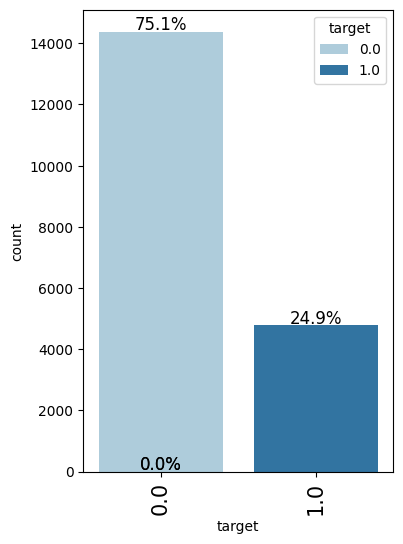

In [101]:
labeled_barplot(df, "target", perc=True)

* The target variable is imbalanced, with 75% of enrollees not seeking jobs and possibly just interested in new technologies.

`city_development_index`

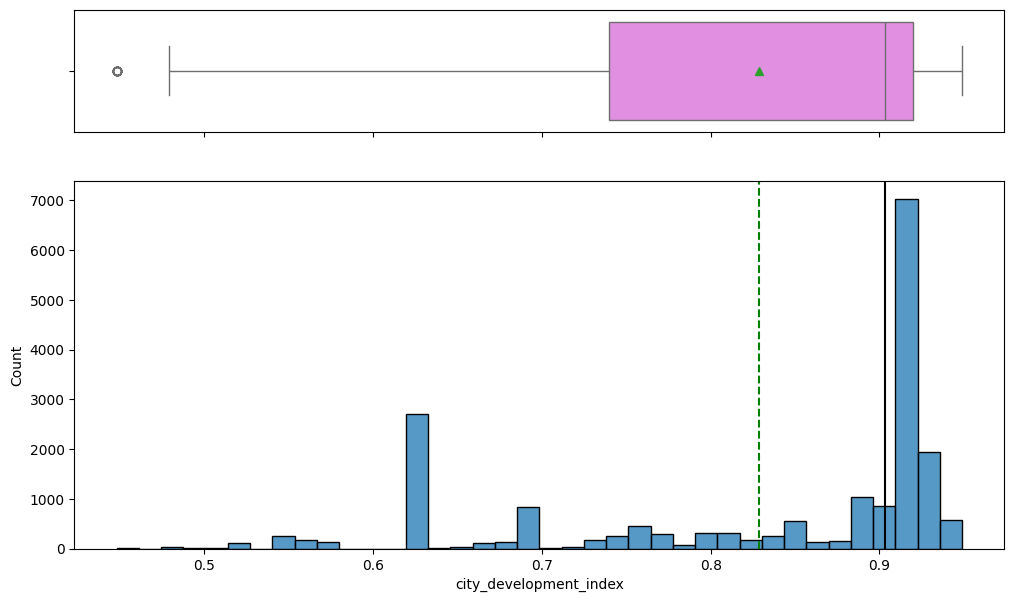

In [102]:
histogram_boxplot(df, "city_development_index")

* Distribution of city_development_index is left-skewed.
* Cities with city_development_index less than ~0.45 are outliers - such cities might be underdeveloped or tier 3 cities.

In [103]:
df[df["city_development_index"] < 0.45]

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
1523,8238,city_33,0.448,NaN,Has relevent experience,Part time course,Graduate,STEM,10,50-99,NGO,>4,48,1.0
4744,30985,city_33,0.448,NaN,No relevent experience,Full time course,Graduate,STEM,2,NaN,NaN,never,43,1.0
5010,27970,city_33,0.448,Male,No relevent experience,no_enrollment,Graduate,STEM,1,NaN,NaN,never,73,1.0
5265,31194,city_33,0.448,NaN,No relevent experience,NaN,High School,NaN,5,NaN,Pvt Ltd,never,86,1.0
5567,598,city_33,0.448,NaN,Has relevent experience,Part time course,Masters,STEM,6,NaN,NaN,1,18,1.0
6127,18564,city_33,0.448,NaN,No relevent experience,Full time course,Graduate,STEM,4,NaN,Public Sector,4,32,1.0
7724,31179,city_33,0.448,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,28,0.0
7864,26838,city_33,0.448,Male,Has relevent experience,no_enrollment,Graduate,STEM,8,NaN,NaN,>4,74,0.0
9134,4858,city_33,0.448,NaN,No relevent experience,Part time course,Masters,Other,2,<10,NGO,1,23,1.0
10401,19463,city_33,0.448,Male,No relevent experience,no_enrollment,Graduate,STEM,5,10000+,Pvt Ltd,2,36,0.0


* All such records with a city development index less than 0.45 are from city_33, hence they seem to represent true pattern and we don't need to treat them as outliers.

`training_hours`

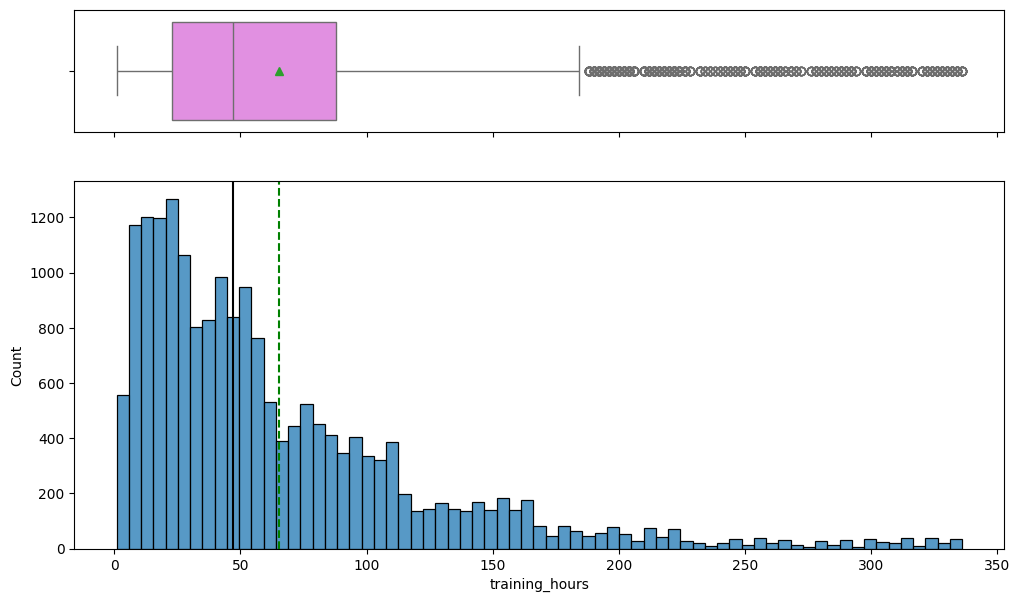

In [104]:
histogram_boxplot(df, "training_hours")

* Distribution of training_hours is right-skewed with many outliers.
* From the boxplot, we can see that enrollees with more than ~175hrs of training are outliers.

`gender`

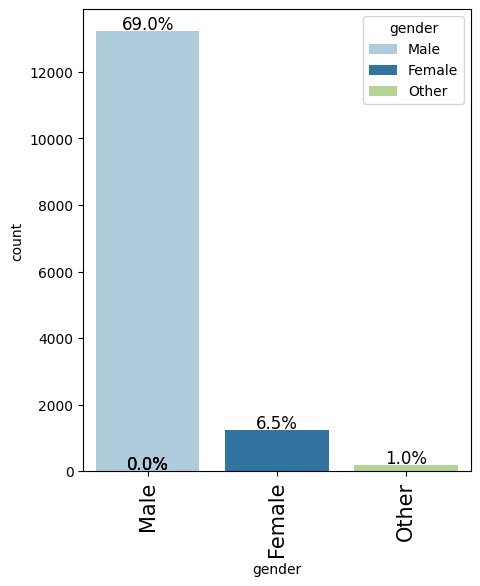

In [105]:
labeled_barplot(df, "gender", perc=True)

In [106]:
# 69% of the enrollees are male

`relevent_experience`

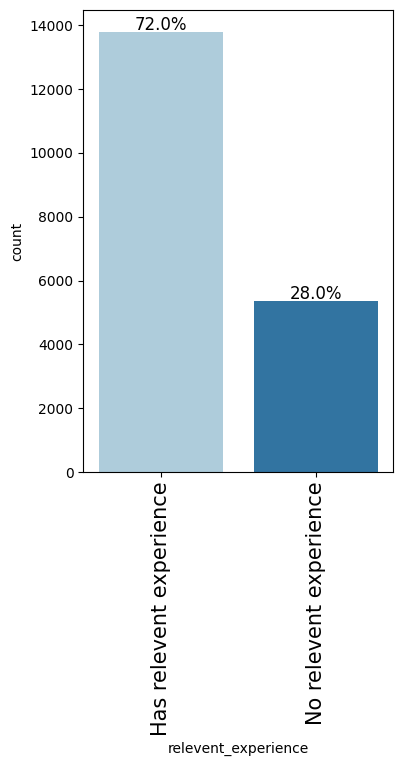

In [107]:
labeled_barplot(df, "relevent_experience", perc=True)

* 72% of the enrollees have some relevant experience.

`company_size`

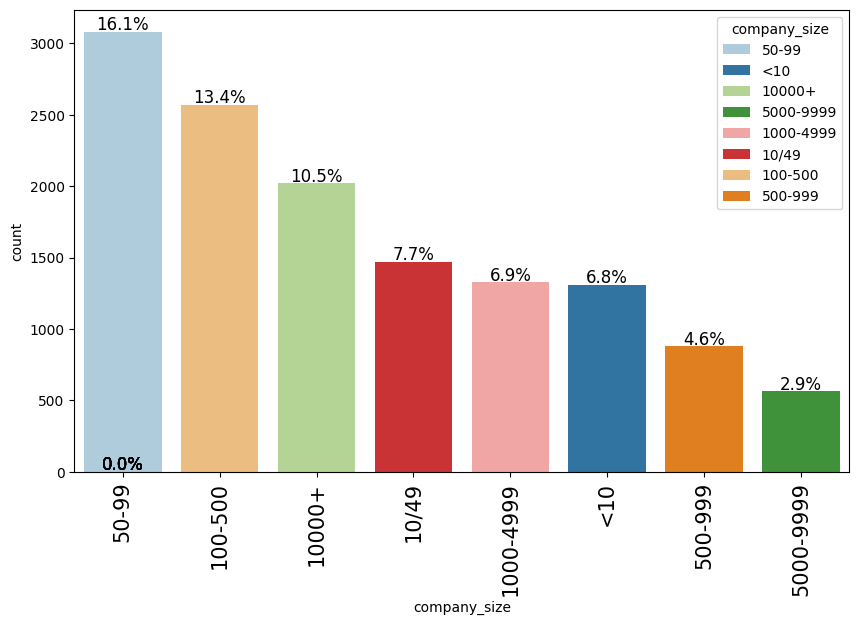

In [108]:
labeled_barplot(df, "company_size", perc=True)

* 16.1% of the enrollees have worked in a company with 50-99 employees, followed by 13.4% of the enrollees who have worked in a company with 100-500.

### Bivariate Analysis

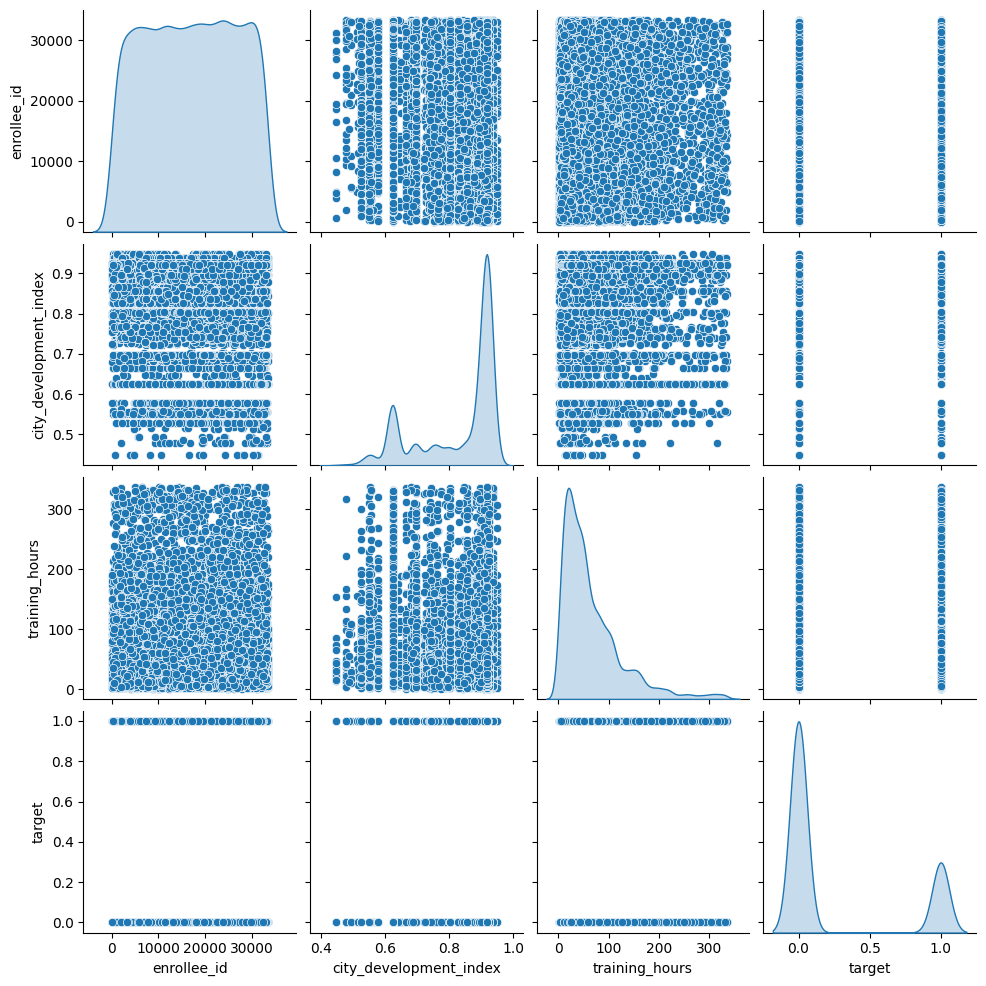

In [109]:
sns.pairplot(data=df, diag_kind="kde")
plt.show()

* Encoding 1 and 0 to 'yes' and 'no' respectively, for analysis.

In [110]:
df["target"].replace(1, "yes", inplace=True)
df["target"].replace(0, "no", inplace=True)

`target vs gender`

target     no   yes    All
gender                    
All     11262  3388  14650
Male    10209  3012  13221
Female    912   326   1238
Other     141    50    191
------------------------------------------------------------------------------------------------------------------------


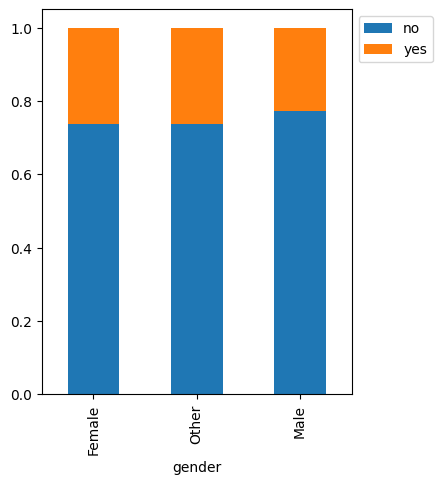

In [111]:
stacked_barplot(df, "gender", "target")

* Females followed by other gender enrollees are the ones actively looking for a job change.
* Let's add the unknown as a category (in place of missing values) and see if there's a change in observations.

In [112]:
df["gender"] = df["gender"].replace(np.nan, "unknown")

target      no   yes    All
gender                     
All      14381  4777  19158
Male     10209  3012  13221
unknown   3119  1389   4508
Female     912   326   1238
Other      141    50    191
------------------------------------------------------------------------------------------------------------------------


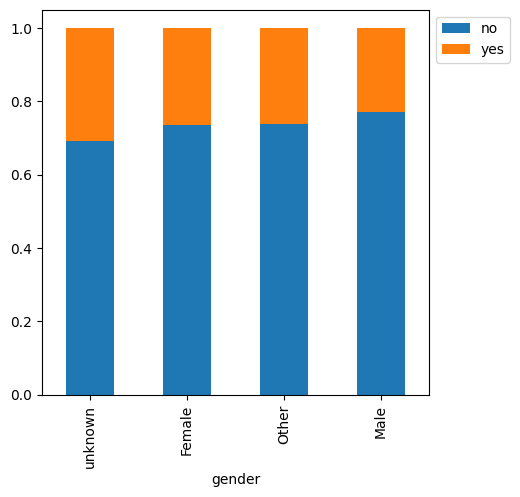

In [113]:
stacked_barplot(df, "gender", "target")

* 'Unknown' gender has the most percentage of enrollees looking for a job change.

`target vs relevant_experience`

target                      no   yes    All
relevent_experience                        
All                      14381  4777  19158
Has relevent experience  10831  2961  13792
No relevent experience    3550  1816   5366
------------------------------------------------------------------------------------------------------------------------


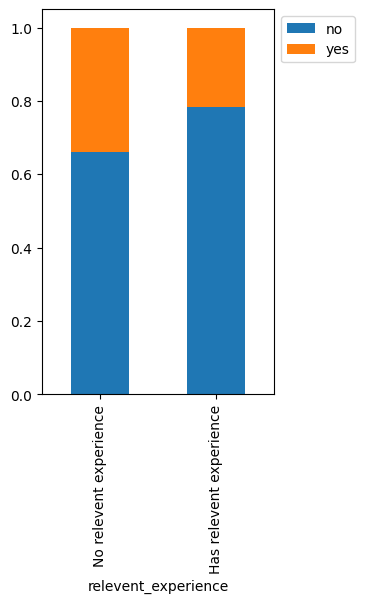

In [114]:
stacked_barplot(df, "relevent_experience", "target")

* 35% of the enrollees who do not have relevant experience are the ones looking for a job change.
* Such enrollees might be freshers looking for opportunities.
* 20% of the enrollees who have relevant experience are also looking for a job change such enrollees after upskilling might be looking for new roles with the newly acquired skills.

`target vs company_type`

target                  no   yes    All
company_type                           
All                  10625  2393  13018
Pvt Ltd               8042  1775   9817
Public Sector          745   210    955
Early Stage Startup    461   142    603
Funded Startup         861   140   1001
NGO                    424    97    521
Other                   92    29    121
------------------------------------------------------------------------------------------------------------------------


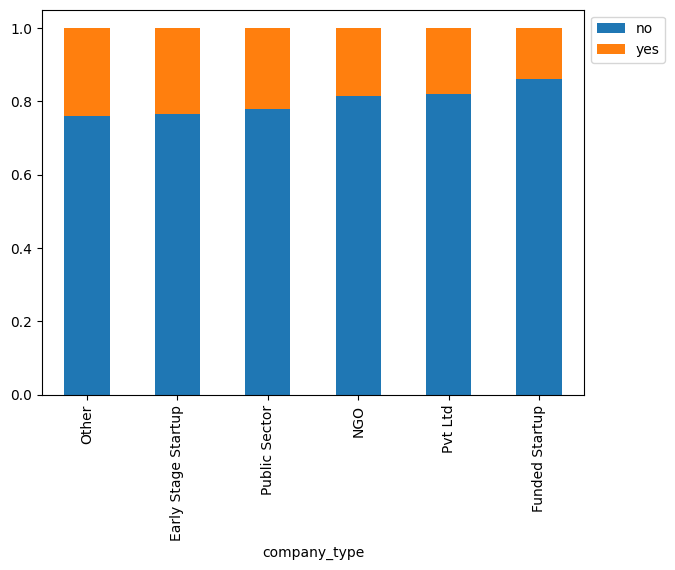

In [115]:
stacked_barplot(df, "company_type", "target")

* Enrollees from funded startups are the ones with less interest a possible reason being their startup just got funded, and they are looking for growth there and just want to upskill by undergoing the training.
* Across all types of companies/sectors ~20% of the enrollees are looking for a job change.

`target vs last_new_job`

target           no   yes    All
last_new_job                    
All           14112  4623  18735
1              5915  2125   8040
never          1713   739   2452
2              2200   700   2900
>4             2690   600   3290
3               793   231   1024
4               801   228   1029
------------------------------------------------------------------------------------------------------------------------


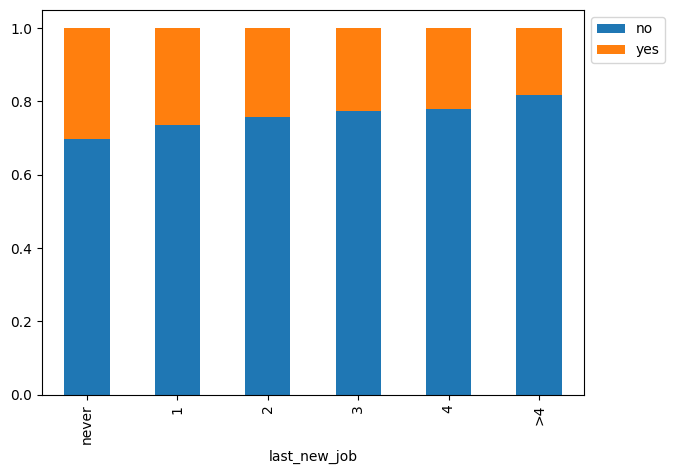

In [116]:
stacked_barplot(df, "last_new_job", "target")

* Our earlier thought of 'never' representing freshers or those who are not working right now seems true as they are the ones most interested in a job change(looking for a start).

`target vs city_development_index`

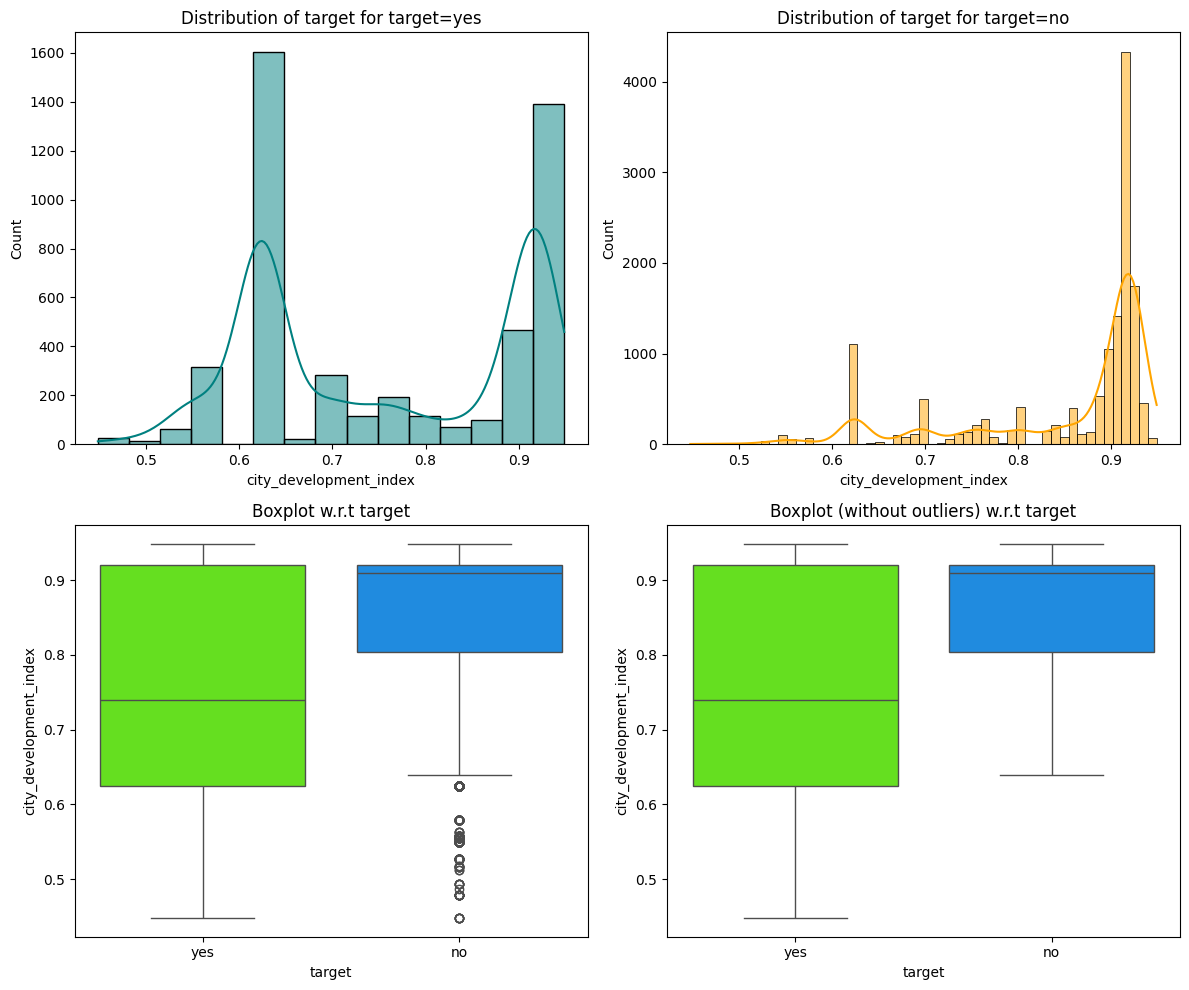

In [117]:
distribution_plot_wrt_target(df, "city_development_index", "target")

* There's a stark difference between the enrollees looking for a job and an enrollee not looking for a job.
* Enrollee from a city with a higher development index would be less likely to look for a change in a job as compared to the enrollee coming from a city with a lower development index.
* Enrollees coming from cities with a low development index might be looking for better opportunities in metropolitan cities by upskilling themselves after undergoing the training.

## Data Preprocessing

* `enrollee_id:` enrollee_id being a unique identifier doesn't add any meaning to the analysis and can be dropped.

In [118]:
df.drop(["enrollee_id"], axis=1, inplace=True)

### Encoding categorical variables

In [119]:
df["city"].nunique()

123

* There are 123 unique cities in data, we can reduce the levels by grouping them into 3 major categories:
  * Developed city - with city development index greater than 0.90
  * Developing city - with city development index between 0.74 and 0.90
  * Under-Developed city - with city development index between 0.4 and 0.74

In [120]:
df["city_development_index"].describe()

,city_development_index
count,19158.000000
mean,0.828848
std,0.123362
min,0.448000
25%,0.740000
50%,0.903000
75%,0.920000
max,0.949000


In [121]:
# Discretize variable into equal-sized buckets based on quantiles
df["city"] = pd.qcut(
    df["city_development_index"],
    q=[0, 0.25, 0.5, 1],
    labels=["Under_Developed", "Developing", "Developed"],
)

In [122]:
df["city"].value_counts()

,count
city,
Developed,9561
Under_Developed,4838
Developing,4759


* 123 unique values have been binned into 3 categories.

In [123]:
data1 = df.copy()

In [124]:
data1.head()

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,Developed,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,yes
1,Developing,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,no
2,Under_Developed,0.624,unknown,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,no
3,Developing,0.789,unknown,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,yes
4,Developing,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,no


### Data Preparation for Modeling

In [125]:
X = data1.drop(["target"], axis=1)
y = data1["target"].apply(lambda x: 1 if x == "yes" else 0)

- By default, `pandas` infers the missing values to be of either float ('nan') or 'unknown' data type.
- We'll convert it to `pd.NA`, which is `pandas` data type for NaN.

In [126]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# then we split the temporary set into training and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print(X_train.shape, X_val.shape, X_test.shape)

(11494, 12) (3832, 12) (3832, 12)


In [127]:
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 11494
Number of rows in validation data = 3832
Number of rows in test data = 3832


- We'll store the indices of the train, validation, and test for later use.

In [128]:
train_index = set(X_train.index)
val_index = set(X_val.index)
test_index = set(X_test.index)

### Missing Value Treatment

In [129]:
X_train.isnull().sum()

,0
city,0
city_development_index,0
gender,0
relevent_experience,0
enrolled_university,217
education_level,272
major_discipline,1677
experience,42
company_size,3566
company_type,3682


In [130]:
X_val.isnull().sum()

,0
city,0
city_development_index,0
gender,0
relevent_experience,0
enrolled_university,85
education_level,99
major_discipline,567
experience,13
company_size,1178
company_type,1223


In [131]:
X_test.isnull().sum()

,0
city,0
city_development_index,0
gender,0
relevent_experience,0
enrolled_university,84
education_level,89
major_discipline,569
experience,10
company_size,1194
company_type,1235


### Creating Dummy Variables

In [132]:
#Concatenating the X_train,X_val and X_test in the row axis.
final_df = pd.concat([X_train,X_val,X_test])

In [133]:
#One-hot encoding the categorical variables.
final_df = pd.get_dummies(final_df, drop_first=True,dtype=int)
print(final_df.shape)

(19158, 57)


* After encoding there are 56 columns.

* We have already stored the indices for the train, validation, and test sets.

* We can now use these indices to retrieve the corresponding subsets from `final_df`.

In [134]:
X_train = final_df.loc[list(train_index)]

X_val = final_df.loc[list(val_index)]

X_test = final_df.loc[list(test_index)]

##Model Building

### Model evaluation criterion

**Model can make wrong predictions as:**
1. Predicting an enrollee is looking for a job change but in reality, the enrollee is not looking for a change - Loss of resources
2. Predicting an enrollee is not looking for a job change but the enrollee is looking for a job change  - Loss of opportunity

**Which case is more important?**
* Predicting an enrollee is not looking for a job change but the enrollee is looking for a job change i.e. losing on a potential candidate as the candidate will not be targeted by the HR team when he should be targeted.

**How to reduce this loss i.e need to reduce False Negatives?**
* Company would want Recall to be maximized, greater the Recall lesser the chances of false negatives.

In [135]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [136]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

### Model building with original data

In [137]:
lr = LogisticRegression(random_state=1)
lr.fit(X_train, y_train)

LogisticRegression(random_state=1)

In [138]:
# Calculating different metrics on train set
log_reg_model_train_perf = model_performance_classification_sklearn(
    lr, X_train, y_train
)
print("Training performance:")
log_reg_model_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.750653,0.0,0.0,0.0


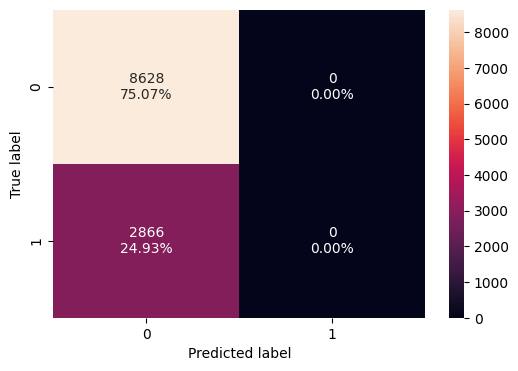

In [139]:
# creating confusion matrix
confusion_matrix_sklearn(lr, X_train, y_train)

In [140]:
# Calculating different metrics on validation set
log_reg_model_val_perf = model_performance_classification_sklearn(lr, X_val, y_val)
print("Validation performance:")
log_reg_model_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.750522,0.0,0.0,0.0


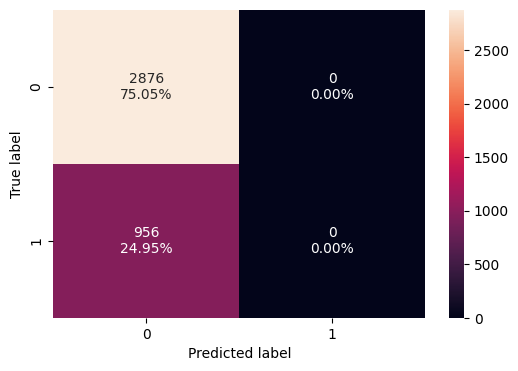

In [141]:
# creating confusion matrix
confusion_matrix_sklearn(lr, X_val, y_val)

- The model is predicting 0 for all inputs.
* Hence, precision, recall, and f1_score are all 0.
- Let's try to understand why that's the case

In [142]:
y_train.value_counts()

,count
target,
0,8628
1,2866


* `y_train` is highly imbalanced with 75% values containing 0 and rest of them 1.
   - We previously checked that the target variable `y` was imbalanced in the same ratio.

* As the recall is zero, we can try oversampling (increase training data) to see if the model performance can be improved.

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

- `Stratified K-fold` is a variation of KFold that returns stratified folds. The folds are made by preserving the percentage of samples for each class.

In [143]:
scoring="recall"
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1)
cv_result_bfr = cross_val_score(
    estimator=lr, X=X_train, y=y_train, scoring=scoring, cv=kfold
    )
cv_result_bfr

array([0., 0., 0., 0., 0.])

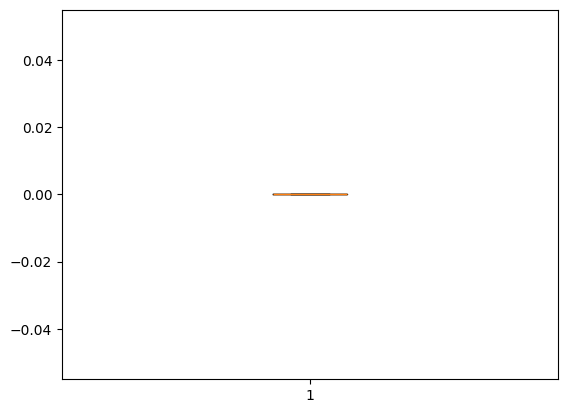

In [144]:
plt.boxplot(cv_result_bfr)
plt.show()

* Performance on training set using the cross-validation is zero.

### Model Building with oversampled data

In [145]:
# Convert boolean columns into integers
X_train = X_train.astype({
    col: 'int' for col in X_train.select_dtypes(include='bool').columns
})

X_test = X_test.astype({
    col: 'int' for col in X_test.select_dtypes(include='bool').columns
})

In [146]:
print("Before Oversampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Oversampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

sm = SMOTE(
    sampling_strategy=1, k_neighbors=5, random_state=1
)  # Synthetic Minority Over Sampling Technique
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After Oversampling, counts of label 'Yes': {}".format(sum(y_train_over == 1)))
print("After Oversampling, counts of label 'No': {} \n".format(sum(y_train_over == 0)))


print("After Oversampling, the shape of train_X: {}".format(X_train_over.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before Oversampling, counts of label 'Yes': 2866
Before Oversampling, counts of label 'No': 8628 

After Oversampling, counts of label 'Yes': 8628
After Oversampling, counts of label 'No': 8628 

After Oversampling, the shape of train_X: (17256, 57)
After Oversampling, the shape of train_y: (17256,) 



In [147]:
log_reg_over = LogisticRegression(random_state=1)

# Training the basic logistic regression model with training set
log_reg_over.fit(X_train_over, y_train_over)

LogisticRegression(random_state=1)

In [148]:
# Calculating different metrics on train set
log_reg_over_train_perf = model_performance_classification_sklearn(
    log_reg_over, X_train_over, y_train_over
)
print("Training performance:")
log_reg_over_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.765241,0.6844,0.816397,0.744594


In [149]:
# Calculating different metrics on validation set
log_reg_over_val_perf = model_performance_classification_sklearn(
    log_reg_over, X_val, y_val
)
print("validation performance:")
log_reg_over_val_perf

validation performance:


,Accuracy,Recall,Precision,F1
0,0.679019,0.169456,0.270903,0.208494


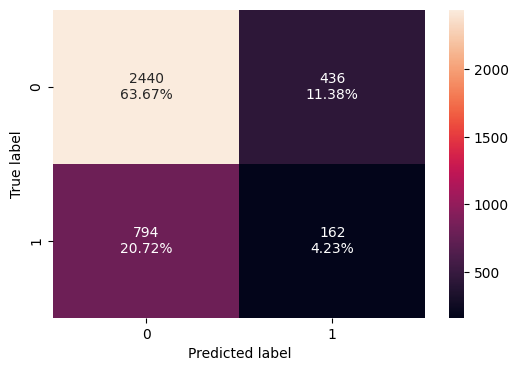

In [150]:
# creating confusion matrix
confusion_matrix_sklearn(log_reg_over, X_val, y_val)

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

In [151]:
scoring = "recall"
kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # Setting number of splits equal to 5
cv_result_over = cross_val_score(
    estimator=log_reg_over, X=X_train_over, y=y_train_over, scoring=scoring, cv=kfold
)
cv_result_over

array([0.68192352, 0.66724638, 0.67304348, 0.68424102, 0.70451912])

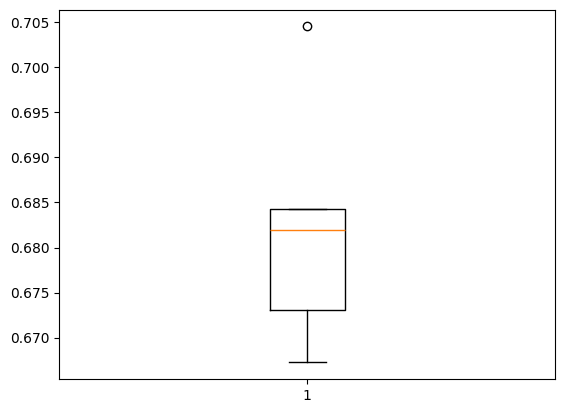

In [152]:
# Plotting boxplots for CV scores of model defined above
plt.boxplot(cv_result_over)
plt.show()

* Performance of model on training set varies between 0.63 to 0.64, which is an improvement from the model built on the original dataset


* Performance on the training set improved but the model is not able to replicate the same for the validation set, which indicates that the model is overfitting
* Lets try regularization to see if overfitting can be reduced



### Regularization

In [153]:
# Choose the type of classifier.
lr_estimator = LogisticRegression(random_state=1, solver="saga")

# Grid of parameters to choose from
parameters = {"C": np.arange(0.1, 1.1, 0.1)}

# Run the grid search
grid_obj = GridSearchCV(lr_estimator, parameters, scoring="recall")
grid_obj = grid_obj.fit(X_train_over, y_train_over)

# Set the clf to the best combination of parameters
lr_estimator = grid_obj.best_estimator_

# Fit the best algorithm to the data.
lr_estimator.fit(X_train_over, y_train_over)

LogisticRegression(C=np.float64(0.2), random_state=1, solver='saga')

In [154]:
# Calculating different metrics on train set
log_reg_reg_train_perf = model_performance_classification_sklearn(
    lr_estimator, X_train_over, y_train_over
)
print("Training performance:")
log_reg_reg_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.713607,0.662146,0.738114,0.698069


In [155]:
# Calculating different metrics on validation set
log_reg_reg_val_perf = model_performance_classification_sklearn(
    lr_estimator, X_val, y_val
)
print("Validation performance:")
log_reg_reg_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.639092,0.247908,0.263041,0.25525


* After regularization, overfitting has reduced to some extent but, still not useful.

### Model Building with undersampled data

In [156]:
rus = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)


print("Before UnderSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before UnderSampling, counts of label '0': {} \n".format(sum(y_train == 0)))


print("After UnderSampling, counts of label '1': {}".format(sum(y_train_un == 1)))
print("After UnderSampling, counts of label '0': {} \n".format(sum(y_train_un == 0)))


print("After UnderSampling, the shape of train_X: {}".format(X_train_un.shape))
print("After UnderSampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before UnderSampling, counts of label '1': 2866
Before UnderSampling, counts of label '0': 8628 

After UnderSampling, counts of label '1': 2866
After UnderSampling, counts of label '0': 2866 

After UnderSampling, the shape of train_X: (5732, 57)
After UnderSampling, the shape of train_y: (5732,) 



In [157]:
log_reg_under = LogisticRegression(random_state=1)
log_reg_under.fit(X_train_un, y_train_un)

LogisticRegression(random_state=1)

In [158]:
# Calculating different metrics on train set
log_reg_under_train_perf = model_performance_classification_sklearn(
    log_reg_under, X_train_un, y_train_un
)
print("Training performance:")
log_reg_under_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.535939,0.517795,0.537292,0.527363


In [159]:
# Calculating different metrics on validation set
log_reg_under_val_perf = model_performance_classification_sklearn(
    log_reg_under, X_val, y_val
)
print("Validation performance:")
log_reg_under_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.52166,0.528243,0.267621,0.355259


* Model has given a generalized performance on training and validation set

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

In [160]:
scoring = "recall"
kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # Setting number of splits equal to 5
cv_result_under = cross_val_score(
    estimator=log_reg_under, X=X_train_un, y=y_train_un, scoring=scoring, cv=kfold
)
cv_result_under

array([0.4991274 , 0.47038328, 0.51308901, 0.4921466 , 0.51483421])

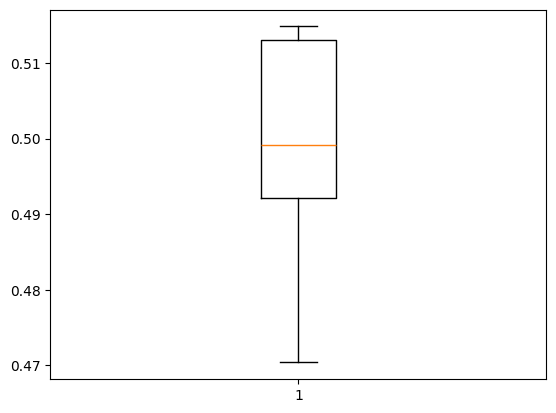

In [161]:
# Plotting boxplots for CV scores of model defined above
plt.boxplot(cv_result_under)
plt.show()

* Performance of model on training set varies between 0.5 to 0.52, which is an improvement from the initial model (without oversampling)

## Model Performance Comparison and Final Model Selection

In [162]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        log_reg_model_train_perf.T,
        log_reg_over_train_perf.T,
        log_reg_reg_train_perf.T,
        log_reg_under_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.750653,0.765241,0.713607,0.535939
Recall,0.000000,0.684400,0.662146,0.517795
Precision,0.000000,0.816397,0.738114,0.537292
F1,0.000000,0.744594,0.698069,0.527363


In [163]:
# Validation performance comparison

models_train_comp_df = pd.concat(
    [
        log_reg_model_val_perf.T,
        log_reg_over_val_perf.T,
        log_reg_reg_val_perf.T,
        log_reg_under_val_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Validation performance comparison:")
models_train_comp_df

Validation performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.750522,0.679019,0.639092,0.521660
Recall,0.000000,0.169456,0.247908,0.528243
Precision,0.000000,0.270903,0.263041,0.267621
F1,0.000000,0.208494,0.255250,0.355259


* Initially, the first model used the original data without addressing imbalance issues. After applying imbalance handling techniques and regularization, recall improved from 0 to 0.52.

* Compared to other models, the model with the undersampled data performs well.

* The logistic regression model on undersampled data has given a generalized performance with the highest recall on validation data, so we will consider it as our final model

### Test Performance

**Now we have our final model, let's find out how our model is performing on unseen test data**

In [164]:
# Calculating different metrics on validation set
log_reg_under_test_perf = model_performance_classification_sklearn(
    log_reg_under, X_test, y_test
)
print("Test performance:")
log_reg_under_test_perf

Test performance:


,Accuracy,Recall,Precision,F1
0,0.499478,0.472251,0.241823,0.319858


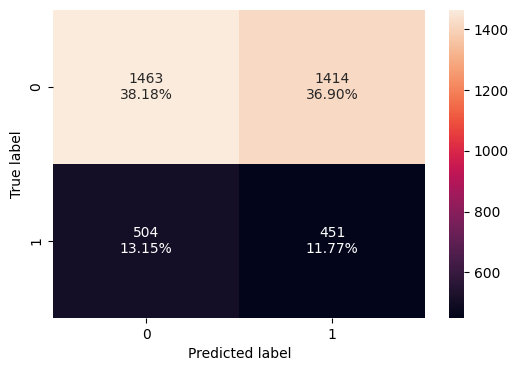

In [165]:
# creating confusion matrix
confusion_matrix_sklearn(log_reg_under, X_test, y_test)

- Model trained with undersampled data has given generalised performance on the test set

### Coefficient Interpretation

In [166]:
# let us check the coefficients and intercept of the model (lin. and log. reg. sklearn)

coef_df = pd.DataFrame(
    np.append(log_reg_under.coef_, log_reg_under.intercept_),
    index=X_train.columns.tolist() + ["Intercept"],
    columns=["Coefficients"],
)
coef_df.T

,city_development_index,training_hours,city_Developing,city_Developed,gender_Male,gender_Other,gender_unknown,relevent_experience_No relevent experience,enrolled_university_Part time course,enrolled_university_no_enrollment,...,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never,Intercept
Coefficients,0.039378,-0.000845,0.1163,0.011495,-0.00383,-0.007633,0.004893,0.139756,-0.27854,-0.089232,...,0.006094,0.036566,-0.085921,0.081021,-0.019761,-0.204214,-0.217539,-0.162062,-0.179547,0.033058


* The coefficients of the logistic regression model are in terms of log(odd), to find the odds we have to take the exponential of the coefficients.
* Therefore, **odds =  exp(b)**
* The percentage change in odds is given as **odds = (exp(b) - 1) * 100**

In [167]:
# converting coefficients to odds
#odds = np.exp(log_reg_under.params)
odds = np.exp(log_reg_under.coef_[0])

# finding the percentage change
perc_change_odds = (np.exp(log_reg_under.coef_[0]) - 1) * 100

# removing limit from number of columns to display
pd.set_option("display.max_columns", None)

# adding the odds to a dataframe
odds_df = pd.DataFrame({"Odds": odds, "Change_odd%": perc_change_odds}, index=X_train.columns).T

odds_df

,city_development_index,training_hours,city_Developing,city_Developed,gender_Male,gender_Other,gender_unknown,relevent_experience_No relevent experience,enrolled_university_Part time course,enrolled_university_no_enrollment,education_level_High School,education_level_Masters,education_level_Phd,education_level_Primary School,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,experience_10,experience_11,experience_12,experience_13,experience_14,experience_15,experience_16,experience_17,experience_18,experience_19,experience_2,experience_20,experience_3,experience_4,experience_5,experience_6,experience_7,experience_8,experience_9,experience_<1,experience_>20,company_size_100-500,company_size_1000-4999,company_size_10000+,company_size_50-99,company_size_500-999,company_size_5000-9999,company_size_<10,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never
Odds,1.040163,0.999155,1.123333,1.011561,0.996177,0.992396,1.004905,1.149993,0.756888,0.914634,1.150885,1.028807,1.198564,1.116093,0.807323,1.066898,1.057503,0.947129,1.003062,1.283217,1.086693,1.106133,0.988748,0.889236,1.015451,1.214264,0.983768,1.199589,0.964711,0.960154,0.945944,0.822876,0.891932,1.131188,0.973561,0.937759,0.885663,0.907962,0.831538,1.037970,0.936501,1.131645,1.026887,0.988193,1.133564,1.157419,0.858790,1.357217,1.006113,1.037242,0.917667,1.084393,0.980433,0.815288,0.804496,0.850388,0.835649
Change_odd%,4.016315,-0.084475,12.333284,1.156114,-0.382290,-0.760372,0.490450,14.999321,-24.311230,-8.536643,15.088477,2.880705,19.856393,11.609325,-19.267664,6.689782,5.750284,-5.287071,0.306196,28.321688,8.669297,10.613322,-1.125187,-11.076419,1.545064,21.426359,-1.623202,19.958873,-3.528866,-3.984584,-5.405629,-17.712380,-10.806808,13.118786,-2.643914,-6.224127,-11.433728,-9.203781,-16.846222,3.796955,-6.349898,13.164496,2.688712,-1.180679,13.356356,15.741850,-14.121028,35.721740,0.611276,3.724227,-8.233344,8.439337,-1.956723,-18.471233,-19.550374,-14.961155,-16.435098


* `city_developement_index`: Holding all other features constant a 1 unit change in city_development_index will increase the odds of a person looking for a job by ~1.05 times or a ~5.5% increase in odds of looking for a job change

* `training_hours`: Holding all other features constant a 1 unit change in training_hours will decrease the odds of a person looking for a job by ~0.99 times or a ~0.08% decrease in odds of a person looking for a job change

* `city - developing/developed`:
    * The odds of a person who is from a developing city looking for a job change is ~1.10 times more than a person who is from an under-developed city or a ~10.7% more odds than a person who is from an under-developed city.  (keeping under-developed cities as a reference).

    * Similarly, The odds of a person who is from a developed city looking for a job change is ~1.01 times more than a person who is from an under-developed city or a ~1.03% more odds than a person who is from an under-developed city (keeping under-developed cities as a reference).

* `gender - male/other` -  The odds of a male looking for a job change is ~1.16% more than a female. Similarly, The odds of a person from 'other' gender looking for a job change is ~0.52% lesser than a female. (keeping females as a reference).

* `relevent_experience` - No relevant experience: The odds of a person who has no relevant job experience looking for a job change ~1.14 times higher than the person with some relevant experience or is ~14.69% higher than a person who has some relevant experience.

**Interpretation for other attributes can be made similarly.**

## Conclusions and Business Recommendations

* As we saw in our analysis and also the logistic regression model shows that several training hours have a very less impact on a person looking to change a job, so the company should not give high importance to this attribute while looking to hire a person.
* A person from an under-developed city would highly be looking for a switch and if an enrollee fulfills the criterion of job role they should be given higher preference than enrollees from other cities (developed and underdeveloped).
* To have a diverse culture in the company enrollees from other genders can be hired as they are more likely to look for a new job role.
* Enrollees with no relevant experience or no experience - generally freshers are more likely to look for a job and such enrollees on fulfilling the criterion of job should be the ones the company should focus on.
* Enrollees from early-stage startups, public sectors, or NGOs are more likely to switch to a new role as compared to the ones from the Private sector or Funded startups.
* Company size is an important aspect, those enrollees who have been in a company with a higher number of employees (1000-5000 or 10000+) are the ones who are actively looking for a switch - Such enrollees might now be looking for higher roles in team management, or it is much easier for such enrollees to fit into a workplace with so higher exposure to the working environment.